# Wang et al. 2020: multiview Inception-v3 for ABUS

## 1. Paper summary and reference

Y. Wang, E. J. Choi, Y. Choi, H. Zhang, G. Y. Jin, S.-B. Ko, *Breast cancer classification in automated breast ultrasound
using multiview convolutional neural network with transfer learning*, Ultrasound in Medicine & Biology 46(5):1119-1132
(2020), [doi:10.1016/j.ultrasmedbio.2020.01.001](https://doi.org/10.1016/j.ultrasmedbio.2020.01.001).

Lesion patches are cropped along a box in the coronal and transverse views and classified with an ImageNet-pretrained
Inception-v3. **Multiview CNN A** stacks coronal, transverse and transverse patches as the three image channels. **Multiview
CNN B** gives each view its own backbone and joins the features before the first dense layer.

We implement the patch generation, both multiview CNNs, the two single-view CNNs (Table 2) and CNN A from scratch (Table 3).
We do not run the other backbones, PCA and HOG (Tables 3, 4) or the observer test (Table 5).

The code is `abus_classification/papers/wang2020/`; this notebook imports it.

In [1]:
import sys, os
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from tdsc_abus2023_pytorch import TDSC, DataSplits
from abus_classification.data.lesion_cache import TDSC_PATH
from abus_classification.papers.wang2020 import WangCNN
from abus_classification.papers.wang2020.pipeline import MODES, lesion_patches
from abus_classification.protocol import auc_ci, metrics
from abus_classification import challenge as c

SURFACE, INK, MUTED, ACCENT, REFERENCE, MALIGNANT, BENIGN = "#fcfcfb", "#0b0b0b", "#898781", "#4a3aa7", "#a8a69f", "#eb6834", "#2a78d6"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
RESULTS, SEEDS = Path("../results/wang2020"), (0, 1, 2)
NAMES = {"coronal": "Single view, coronal", "transverse": "Single view, transverse", "cnn_a": "Multiview CNN A", "cnn_b": "Multiview CNN B", "cnn_a_scratch": "CNN A, from scratch"}
test = TDSC(path=TDSC_PATH, split=DataSplits.TEST, download=False)
y = (test.metadata["label"] == "M").to_numpy().astype(int)
runs = {m: [np.load(RESULTS / f"wang2020_{m}_seed{s}.npz") for s in SEEDS] for m in NAMES}
prob = {m: np.stack([r["prob"] for r in rs]) for m, rs in runs.items()}
print(f"test lesions: {len(y)}, malignant: {y.sum()}")

test lesions: 70, malignant: 40


## 2. Implementation details

| Item | Paper | Ours | Status |
|---|---|---|---|
| Box | Drawn by physicians | Official TDSC bounding boxes | **Deviation** |
| Patches | Chosen slices per view: 3085 CNN A patches from 316 lesions, about 10 per lesion | Two slices per view, at 1/3 and 2/3 of the box: 8 CNN A patches per lesion | **Deviation** |
| CNN A input | Coronal, transverse, transverse | Same, every combination | Follows |
| CNN B input | One backbone per view, each patch copied to 3 channels | Same, features concatenated before the first dense layer | Follows |
| Input size | 299 x 299 x 3 | Same; the resize ignores aspect ratio | Resize **assumed** |
| Backbone | Inception-v3, ImageNet, all layers fine-tuned | Same, ImageNet-normalised input | Normalisation **assumed** |
| Head | GAP, dense 256, 128, 2; dropout after the first two; softmax; Xavier uniform | Same; dropout 0.5 | Dropout rate **assumed** |
| Optimiser | Adadelta, batch 32 | Same, lr 1 | lr and loss (cross-entropy) **assumed** |
| Augmentation | Fixed copies: rotations 90, 180, 270, horizontal and vertical flips | One random rotation and flip per sample | **Deviation** |
| Early stopping | Validation AUC not increasing for 5 epochs | Same, keeping the best epoch | Follows |
| From scratch | Xavier uniform on all convolutions, zero biases | torchvision's default Inception-v3 initialisation | **Deviation** |
| Split | Five-fold CV, three folds to fit and one to stop early, on 316 private lesions | Train (100) to fit, Validation (30) to stop early, official Test (70) | **Deviation** |
| Prediction | Not stated per lesion | Mean over a lesion's patch combinations | **Assumed** |

**This run departs from the project protocol.** It fits on 100 volumes rather than 130, because early stopping needs the
Validation split. The paper's scheme also holds out a validation fold.

## 3. Verification of the implementation

`test/papers_tests/test_wang2020.py` checks that patches crop the box in both views, that slices are taken at 1/3 and 2/3,
the view combinations, the head's layer sizes, that augmentation moves all channels together, and that finished runs are not
trained again. Below are the shapes, the combinations, and a check that the stored probabilities give the kernel's own table.

In [2]:
a, b = WangCNN(3, pretrained=False).eval(), WangCNN(6, pretrained=False).eval()
count = lambda net: sum(p.numel() for p in net.parameters())
with torch.no_grad():
    print("CNN A", tuple(a(torch.zeros(2, 3, 299, 299)).shape), f"{count(a):,} parameters, head input {a.fc[0].in_features}")
    print("CNN B", tuple(b(torch.zeros(2, 6, 299, 299)).shape), f"{count(b):,} parameters, head input {b.fc[0].in_features}")
print("dense layers:", [m.out_features for m in a.fc if hasattr(m, "out_features")])
print("patch combinations per lesion:", {m: len(v) for m, v in MODES.items()})
assert a.fc[0].in_features == 2048 and b.fc[0].in_features == 4096

CNN A (2, 2) 22,343,266 parameters, head input 2048


CNN B (2, 2) 44,653,122 parameters, head input 4096
dense layers: [256, 128, 2]
patch combinations per lesion: {'cnn_a': 8, 'cnn_b': 4, 'coronal': 2, 'transverse': 2, 'cnn_a_scratch': 8}


In [3]:
kernel = pd.read_csv(RESULTS / "wang2020_results.csv", index_col=0)
worst = 0
for m in NAMES:
    for s, p in zip(SEEDS, prob[m]):
        worst = max(worst, abs(metrics(y, p)["AUC"] - kernel.loc[f"{m} seed {s}", "AUC"]))
    worst = max(worst, abs(metrics(y, prob[m].mean(0))["AUC"] - kernel.loc[f"{m} mean of seeds", "AUC"]))
print("largest AUC difference from the kernel's table:", round(worst, 5))
assert worst < 1e-4

largest AUC difference from the kernel's table: 3e-05


**Errors in the paper.** We use its tables where it disagrees with itself.

- The text gives the transverse single view the coronal numbers (0.831, 0.800, 0.8874). Table 2 says 0.832, 0.838, 0.9076.
- The CNN B sample counts do not add up: 549 malignant + 468 benign is 1017, not the stated 1525.
- Each fold is said to hold 31 malignant and 33 benign lesions, which gives 320 lesions across five folds, not 316.

## 4. Images

**Method**, redrawn from the paper's Fig. 5, with our patches for one malignant and one benign test lesion.

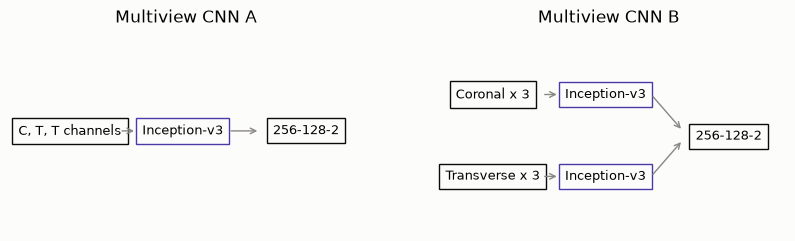

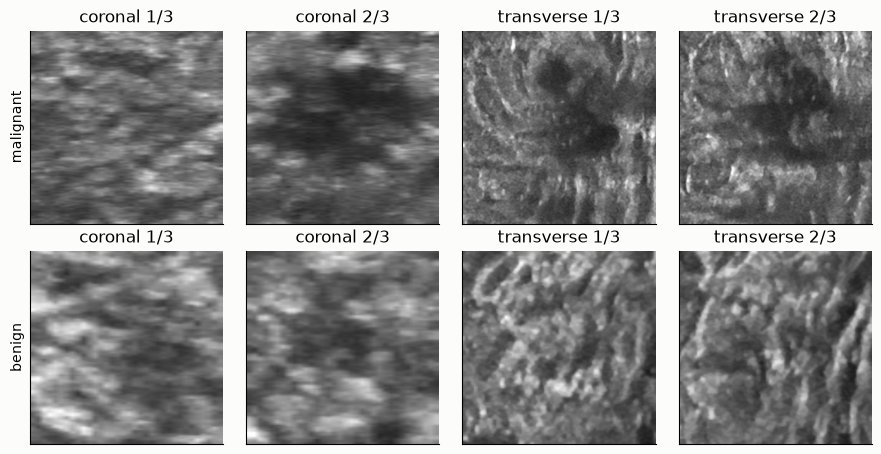

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 2.6))
for a_, title, boxes in ((ax[0], "Multiview CNN A", [("C, T, T channels", .05, .55), ("Inception-v3", .37, .55), ("256-128-2", .72, .55)]), (ax[1], "Multiview CNN B", [("Coronal x 3", .05, .75), ("Transverse x 3", .05, .3), ("Inception-v3", .37, .75), ("Inception-v3", .37, .3), ("256-128-2", .72, .52)])):
    a_.axis("off"); a_.set(xlim=(0, 1), ylim=(0, 1.1), title=title)
    for t, x, yy in boxes:
        a_.text(x + .12, yy, t, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="square,pad=0.5", fc=SURFACE, ec=ACCENT if "Inception" in t else INK))
    for x0, y0, x1, y1 in ([(.31, .55, .36, .55), (.62, .55, .71, .55)] if "A" in title else [(.31, .75, .36, .75), (.31, .3, .36, .3), (.62, .75, .71, .55), (.62, .3, .71, .5)]):
        a_.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", color=MUTED))
plt.show()
picks = [int(np.flatnonzero(y == k)[0]) for k in (1, 0)]
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for row, i, name in zip(axes, picks, ("malignant", "benign")):
    vol, _, _, box = test[i]
    for ax_, p, t in zip(row, lesion_patches(np.asarray(vol), box), ("coronal 1/3", "coronal 2/3", "transverse 1/3", "transverse 2/3")):
        ax_.imshow(p, cmap="gray", vmin=0, vmax=255); ax_.set(xticks=[], yticks=[], title=t)
    row[0].set_ylabel(name)
plt.tight_layout(); plt.show()

**Training curves and ROC curves.** Each coloured line is one seed of CNN A; the ROC curves use probabilities averaged over
the seeds.

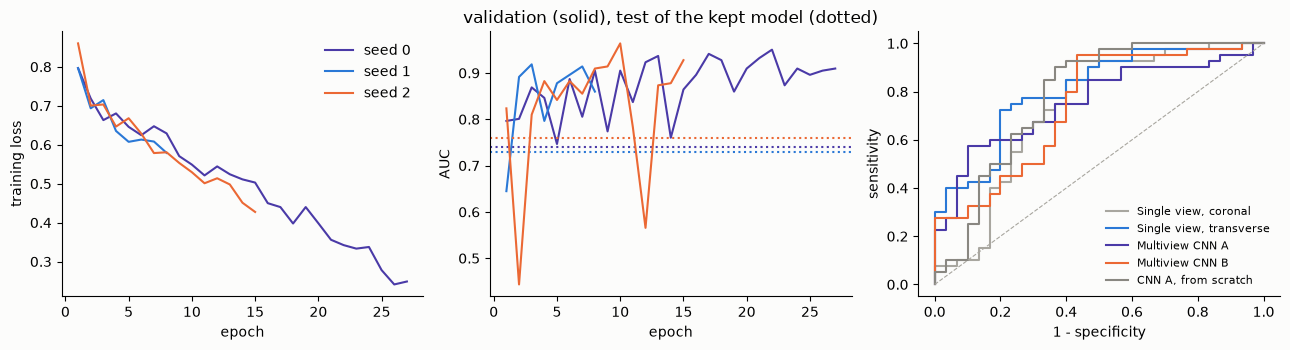

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for s, col in zip(SEEDS, (ACCENT, BENIGN, MALIGNANT)):
    h = pd.read_csv(RESULTS / f"wang2020_cnn_a_seed{s}_history.csv")
    ax[0].plot(h.epoch, h.loss, color=col, label=f"seed {s}"); ax[1].plot(h.epoch, h.val_auc, color=col)
    ax[1].axhline(metrics(y, prob["cnn_a"][s])["AUC"], color=col, ls=":")
ax[0].set(xlabel="epoch", ylabel="training loss"); ax[0].legend(frameon=False)
ax[1].set(xlabel="epoch", ylabel="AUC", title="validation (solid), test of the kept model (dotted)")
for (m, name), col in zip(NAMES.items(), (REFERENCE, BENIGN, ACCENT, MALIGNANT, MUTED)):
    fpr, tpr, _ = roc_curve(y, prob[m].mean(0)); ax[2].plot(fpr, tpr, color=col, label=name)
ax[2].plot([0, 1], [0, 1], color=REFERENCE, ls="--", lw=.8); ax[2].set(xlabel="1 - specificity", ylabel="sensitivity"); ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Tables

The paper's numbers are means over five folds on its private data (Tables 2, 3). To match, **our main figures are means over
seeds of each seed's own AUC**. The paper's standard deviation is across folds and ours across seeds, so they measure
different things. The last columns give the AUC of the probabilities averaged over seeds, with its bootstrap CI.

In [6]:
paper = {"coronal": (.8874, .831, .800), "transverse": (.9076, .832, .838), "cnn_a": (.9468, .886, .876), "cnn_b": (.9346, .865, .848), "cnn_a_scratch": (.9043, .822, .859)}
rows = {}
for m, name in NAMES.items():
    per = pd.DataFrame([metrics(y, p) for p in prob[m]])
    lo, hi = auc_ci(y, prob[m].mean(0))
    rows[name] = {"paper AUC": paper[m][0], "our AUC": per.AUC.mean(), "seed SD": per.AUC.std(), "difference": per.AUC.mean() - paper[m][0],
                  "paper Sens": paper[m][1], "our Sens": per.Sens.mean(), "paper Spec": paper[m][2], "our Spec": per.Spec.mean(), "our Acc": per.Acc.mean(),
                  "seed-mean AUC": metrics(y, prob[m].mean(0))["AUC"], "CI low": lo, "CI high": hi}
table = pd.DataFrame(rows); table = table.T.round(3); table

,paper AUC,our AUC,seed SD,difference,paper Sens,our Sens,paper Spec,our Spec,our Acc,seed-mean AUC,CI low,CI high
"Single view, coronal",0.887,0.727,0.015,-0.160,0.831,1.000,0.800,0.000,0.571,0.724,0.576,0.851
"Single view, transverse",0.908,0.771,0.013,-0.137,0.832,0.725,0.838,0.544,0.648,0.804,0.691,0.904
Multiview CNN A,0.947,0.742,0.016,-0.205,0.886,0.517,0.876,0.722,0.605,0.755,0.631,0.863
Multiview CNN B,0.935,0.713,0.108,-0.221,0.865,0.975,0.848,0.189,0.638,0.739,0.607,0.855
"CNN A, from scratch",0.904,0.761,0.026,-0.143,0.822,1.000,0.859,0.100,0.614,0.778,0.644,0.892


**Per seed, with validation AUC.** The validation AUC is the value that chose the kept model.

In [7]:
pd.DataFrame([{ "configuration": NAMES[m], "seed": s, "validation AUC": float(r["val_auc"]), "test AUC": metrics(y, r["prob"])["AUC"], "test Sens": metrics(y, r["prob"])["Sens"], "test Spec": metrics(y, r["prob"])["Spec"], "share called malignant": (r["prob"] >= .5).mean(), "epochs": len(pd.read_csv(RESULTS / f"wang2020_{m}_seed{s}_history.csv"))} for m, rs in runs.items() for s, r in zip(SEEDS, rs)]).round(3)

,configuration,seed,validation AUC,test AUC,test Sens,test Spec,share called malignant,epochs
0,"Single view, coronal",0,0.751,0.735,1.000,0.000,1.000,9
1,"Single view, coronal",1,0.860,0.710,1.000,0.000,1.000,12
2,"Single view, coronal",2,0.756,0.736,1.000,0.000,1.000,8
3,"Single view, transverse",0,0.882,0.770,0.975,0.300,0.857,14
4,"Single view, transverse",1,0.882,0.784,0.400,0.833,0.300,12
5,"Single view, transverse",2,0.923,0.758,0.800,0.500,0.671,16
6,Multiview CNN A,0,0.950,0.739,0.700,0.667,0.543,27
7,Multiview CNN A,1,0.919,0.728,0.075,0.967,0.057,8
8,Multiview CNN A,2,0.964,0.759,0.775,0.533,0.643,15
9,Multiview CNN B,0,0.882,0.793,0.925,0.567,0.714,14


## 6. Protocol

- **Split**: fit on Train (100), stop early on Validation (30), report on the official Test split (70).
- **Positive class**: malignant.
- **Seeds**: 3, with AUC bootstrap CI.
- **Re-run**: `python -m abus_classification.papers.wang2020`, or push `kaggle/wang2020/` (kernel `wang2020-multiview`, about
  51 minutes on GPU). Finished runs are loaded, not trained again.
- **Results**: `results/wang2020/`: per-seed test probabilities, validation AUC, training histories and
  `wang2020_results.csv`. The weights stay in the kernel's output.

## 7. Open issues

- **The paper's AUC does not reproduce.** CNN A is about 0.2 below the paper. The paper's data is private and its folds
  differ, so this alone does not say whether the method or the data is responsible.
- **The paper's ordering does not reproduce.** The paper finds multiview above single view and pretrained above scratch. Here
  the confidence intervals overlap heavily and the means do not follow that order, so 70 lesions and 3 seeds cannot rank these
  configurations.
- **Validation is far above test.** Selection uses 30 lesions, and the best of many noisy epochs is an optimistic estimate.
  A validation split that is easier than test is also possible. We have not tested either explanation. Cross-validation over
  the 130 volumes would be the next check.
- **The 0.5 threshold is unstable.** Seven of the 15 runs call every test lesion malignant, which gives specificity 0, so accuracy
  and sensitivity move a lot between seeds. Early stopping selects on AUC, which does not constrain the threshold.
- **The patch choice is ours.** The paper does not say how it chose its slices, and it has about 10 patches per lesion to our
  8. We have not tested other choices.
- **Project protocol.** The model never fits on the 30 Validation volumes.

## 8. Challenge benchmark

Multiview CNN A, with probabilities averaged over the seeds. It is here because it is the paper's proposed method, not because
of its test score: the transverse view scores higher. It uses the official boxes, so unlike the challenge teams it does
not locate the lesion itself. It has no segmentation or detection output.

In [8]:
board = c.benchmark({"Wang 2020, CNN A": c.classification(y, prob["cnn_a"].mean(0))})
board[["ACC", "AUC", "Cls_Score", "Cls_Rank"]].round(3)

,ACC,AUC,Cls_Score,Cls_Rank
"Wang 2020, CNN A",0.657,0.755,0.558,5/9
